# Person A: predicting goal difference

All code cells were executed sequentially in a shared IPython session and their real outputs saved here. The accompanying Python scripts reproduce the analysis offline. Read README.md for sources and limitations. Person B variable overlap remains unverified.

## 1. Prepare source records
Run from the extracted project folder. The raw snapshots are included, so no network access is required. Only use this notebook together with the accompanying Python files.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
from prepare_data import prepare
from analysis import main, build_dataset
from evaluation import FEATURES
ROOT = Path.cwd()
prepare()

Prepared 104 World Cup matches, 48 ranks and 1195 historical matches.


## 2. Build the eight pre-match features
The target is A goals minus B goals. Each rolling window uses five matches on strictly earlier dates. Shootouts are excluded from match goals. Rest is a calendar-day difference; it is not elapsed time from final whistle. All sources and name mappings are documented.

In [2]:
dataset, audit, windows = build_dataset()
print("Rows:", len(dataset), "Predictors:", len(FEATURES))
print(FEATURES)
display(dataset.head())
display(audit.head())

Rows: 104 Predictors: 8
['rank_advantage', 'win_rate_diff', 'goals_for_diff', 'goals_against_diff', 'clean_sheet_rate_diff', 'rest_calendar_days_diff', 'home_advantage', 'knockout']


,match_id,match_date,team_a,team_b,rank_advantage,win_rate_diff,goals_for_diff,goals_against_diff,clean_sheet_rate_diff,rest_calendar_days_diff,home_advantage,knockout,goal_difference
0,WC2026_001,2026-06-11,Mexico,South Africa,45,0.6,1.0,-0.8,0.4,2.0,1,0,2
1,WC2026_002,2026-06-11,South Korea,Czech Republic,16,0.0,-2.0,-0.2,0.4,1.0,0,0,1
2,WC2026_003,2026-06-12,Canada,Bosnia and Herzegovina,35,0.4,0.6,-0.2,0.4,1.0,1,0,0
3,WC2026_004,2026-06-12,United States,Paraguay,24,-0.2,0.4,1.4,-0.4,-1.0,1,0,3
4,WC2026_005,2026-06-13,Qatar,Switzerland,-36,-0.2,-1.6,-0.2,0.0,0.0,0,0,0


,match_id,team,target_date,history_count,prior_match_ids,latest_prior_date,rank,rank_release_date,win_rate,avg_goals_for,avg_goals_against,clean_sheet_rate,rest_calendar_days
0,WC2026_001,Mexico,2026-06-11,5,HISTORY_LINE_49240;HISTORY_LINE_49292;HISTORY_...,2026-06-04,15,2026-04-01,0.6,1.8,0.4,0.6,7
1,WC2026_001,South Africa,2026-06-11,5,HISTORY_LINE_49149;HISTORY_LINE_49213;HISTORY_...,2026-06-06,60,2026-04-01,0.0,0.8,1.2,0.2,5
2,WC2026_002,South Korea,2026-06-11,5,HISTORY_LINE_49044;HISTORY_LINE_49239;HISTORY_...,2026-06-03,25,2026-04-01,0.6,1.4,1.0,0.6,8
3,WC2026_002,Czech Republic,2026-06-11,5,HISTORY_LINE_49012;HISTORY_LINE_49189;HISTORY_...,2026-06-04,41,2026-04-01,0.6,3.4,1.2,0.2,7
4,WC2026_003,Canada,2026-06-12,5,HISTORY_LINE_49038;HISTORY_LINE_49236;HISTORY_...,2026-06-05,30,2026-04-01,0.4,1.4,0.6,0.6,7


## 3. Train and test
The earlier 82 matches train the model, and the later 22 matches form the test set. Dates remain together. Earlier test-match results can update pre-match features for later games; coefficients stay fixed. This models prediction before each game rather than an opening-day tournament forecast.

In [3]:
main()
out = ROOT / "outputs"
metrics = json.loads((out / "metrics.json").read_text())
display(pd.DataFrame({k: metrics[k] for k in ["linear_train", "linear_test", "baseline_test"]}).T.round(4))

{
  "status": "Computed from supplied data; source accuracy requires human verification",
  "n_rows": 104,
  "n_train": 82,
  "n_test": 22,
  "test_start_date": "2026-07-02 00:00:00",
  "linear_train": {
    "R2": 0.44453585135940943,
    "RMSE": 1.5513392077969843,
    "MAE": 1.2340155178970202
  },
  "linear_test": {
    "R2": 0.10839107625022149,
    "RMSE": 1.5457331126639122,
    "MAE": 1.2852597427900057
  },
  "baseline_test": {
    "R2": -0.16622077122100753,
    "RMSE": 1.7678185770113808,
    "MAE": 1.4656319290465631
  },
  "intercept": 0.3430372554240034,
  "matrix_condition_number_raw": 294.91595804832644
}
{
  "reason": "Jamaica\u2013South Africa 6 June 2026 source disagreement",
  "main_score_Jamaica_South_Africa": "1\u20131 (SAFA draw; NFT 1\u20131)",
  "alternative_score": "0\u20131 (raw archive)",
  "main_test": {
    "R2": 0.10839107625022149,
    "RMSE": 1.5457331126639122,
    "MAE": 1.2852597427900057
  },
  "alternative_test": {
    "R2": 0.11322441833256336,
   

,R2,RMSE,MAE
linear_train,0.4445,1.5513,1.2340
linear_test,0.1084,1.5457,1.2853
baseline_test,-0.1662,1.7678,1.4656


## 4. Explain coefficients
Hold the other seven variables fixed. Coefficients describe associations, not causation. Rate differences are fractions 0–1: multiply by 0.10 for ten percentage points. Positive ranking advantage means A has a better (lower-numbered) rank. Use VIF to discuss correlated predictors.

In [4]:
display(pd.read_csv(out / "coefficients.csv").round(5))
display(pd.read_csv(out / "training_vif.csv").round(3))
print((out / "coefficient_help.txt").read_text())

TRAINING-MODEL COEFFICIENT INTERPRETATION AIDS
Associations conditional on the other seven predictors; not causal effects.
Rates use 0–1. For 10 percentage points multiply the coefficient by 0.10.
Rank advantage = B rank − A rank; positive means A has a better ranking.
Rest measures calendar days since the previous senior international match.
Home advantage uses the venue country, not the source home/away label.
Holding other predictors fixed, each +1 change in a predictor changes predicted
A-minus-B goal difference by its coefficient (in goals).
Intercept: 0.343037; prediction when all eight inputs equal zero.
Compare raw coefficients only after considering their different units.
Use VIF and correlation outputs to discuss coefficient instability.
rank_advantage: +0.029100 goals per +1 unit.
win_rate_diff: +0.062599 goals per +1 unit.
goals_for_diff: +0.142863 goals per +1 unit.
goals_against_diff: -0.339992 goals per +1 unit.
clean_sheet_rate_diff: -0.411508 goals per +1 unit.
rest_ca

,feature,coefficient,goals_per_training_SD
0,rank_advantage,0.02910,1.03845
1,win_rate_diff,0.06260,0.02230
2,goals_for_diff,0.14286,0.15129
3,goals_against_diff,-0.33999,-0.34907
4,clean_sheet_rate_diff,-0.41151,-0.14868
5,rest_calendar_days_diff,-0.00775,-0.06068
6,home_advantage,1.00539,0.36310
7,knockout,-0.38504,-0.12600


,feature,VIF
0,rank_advantage,2.448
1,win_rate_diff,7.074
2,goals_for_diff,4.323
3,goals_against_diff,3.359
4,clean_sheet_rate_diff,3.149
5,rest_calendar_days_diff,1.050
6,home_advantage,1.186
7,knockout,1.139


## 5. Inspect residuals
Residual = actual minus predicted. Inspect errors and patterns without claiming the small diagnostic sample proves the assumptions.

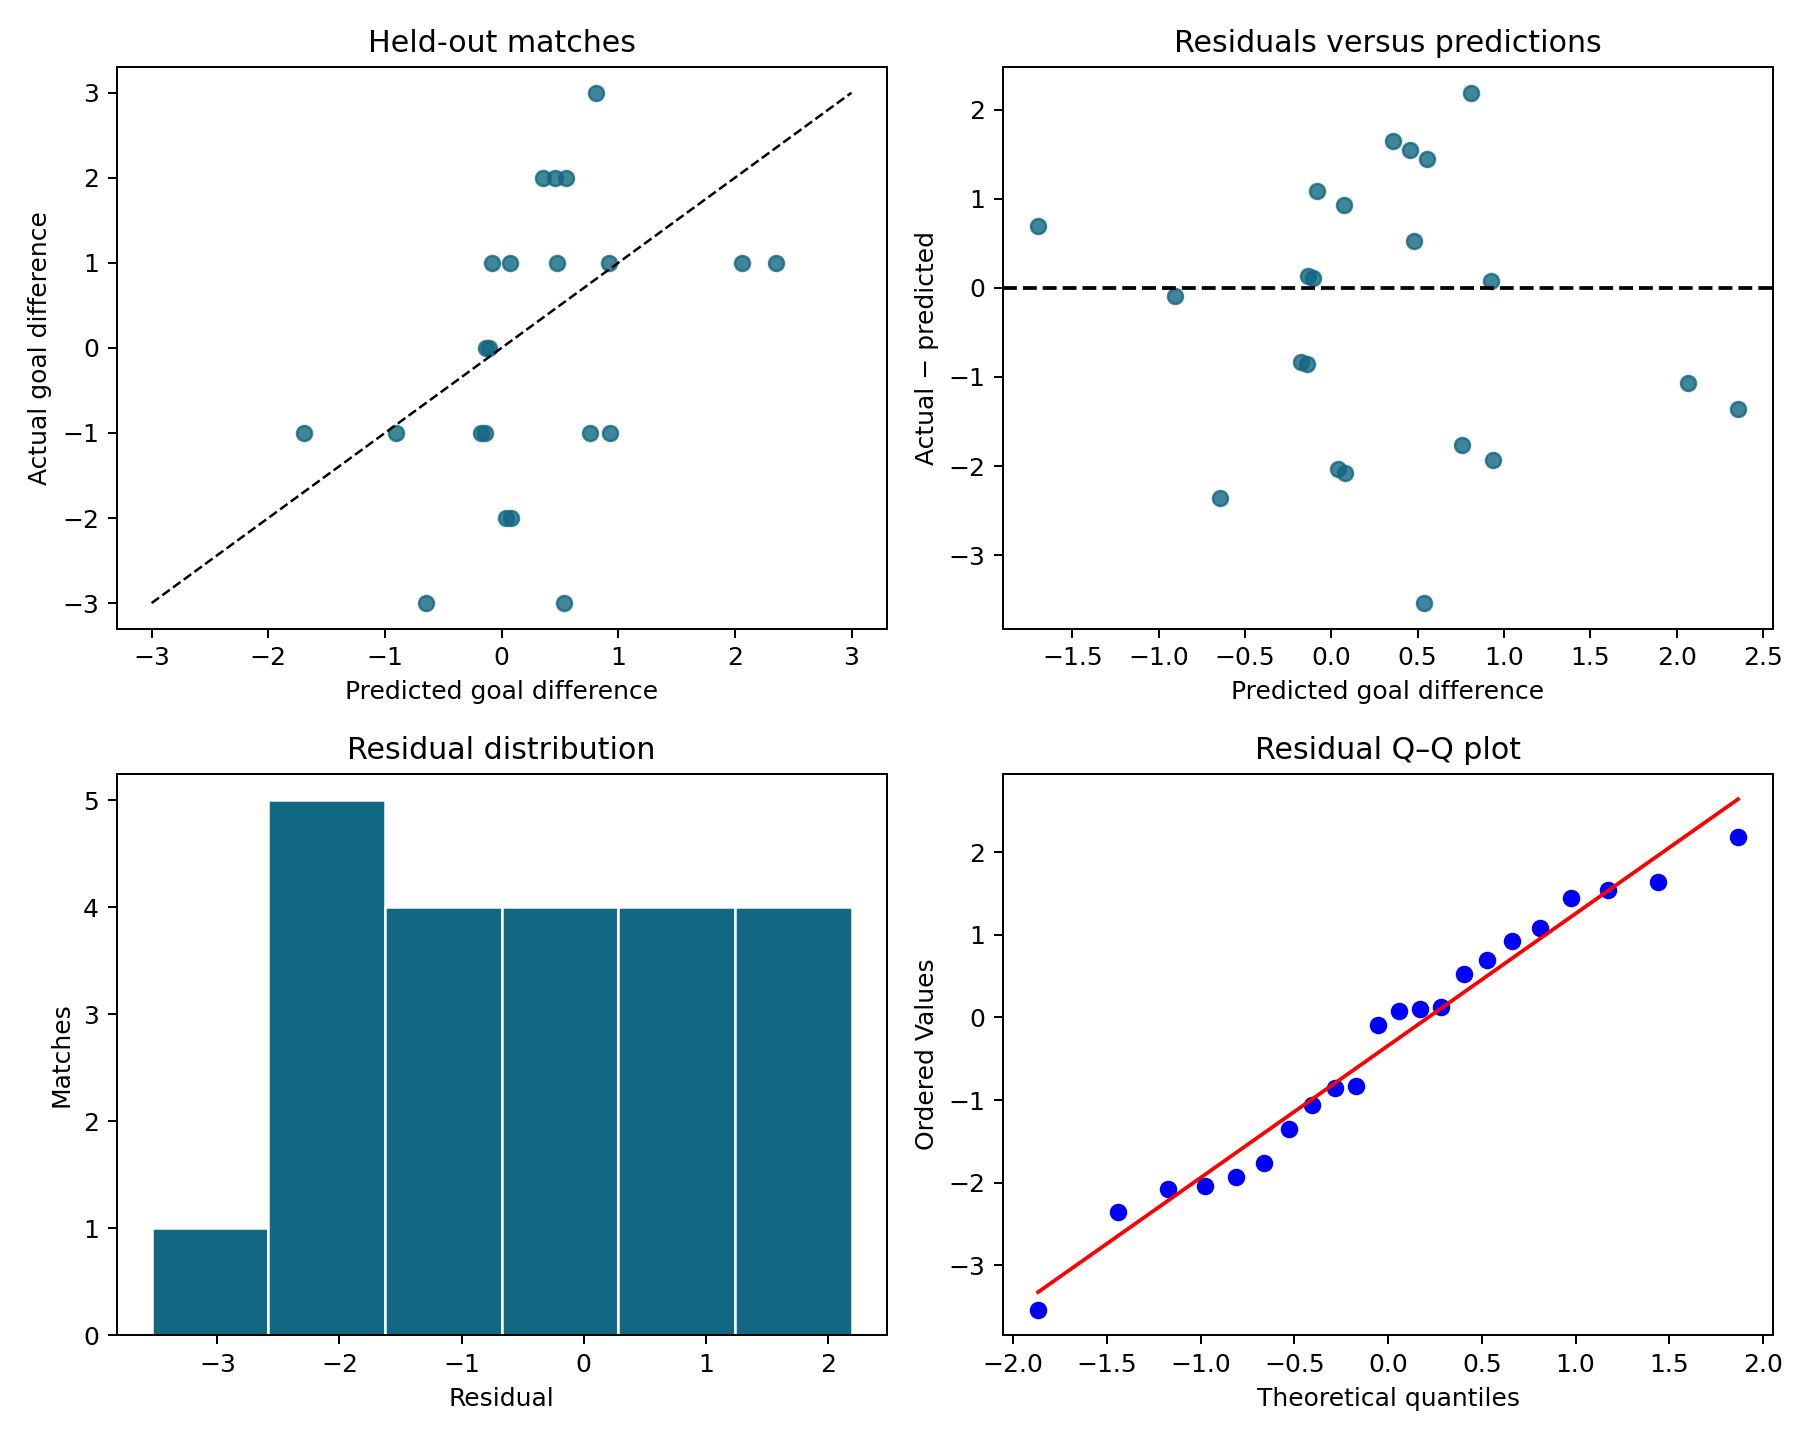

,match_id,match_date,team_a,team_b,goal_difference,prediction,residual_actual_minus_prediction
0,WC2026_083,2026-07-02,Spain,Austria,3,0.808709,2.191291
1,WC2026_084,2026-07-02,Portugal,Croatia,1,0.476008,0.523992
2,WC2026_085,2026-07-02,Switzerland,Algeria,2,0.554390,1.445610
3,WC2026_086,2026-07-03,Australia,Egypt,0,-0.132664,0.132664
4,WC2026_087,2026-07-03,Argentina,Cape Verde,1,2.354689,-1.354689
5,WC2026_088,2026-07-03,Colombia,Ghana,1,2.063775,-1.063775
6,WC2026_089,2026-07-04,Canada,Morocco,-3,-0.647103,-2.352897
7,WC2026_090,2026-07-04,Paraguay,France,-1,-1.697652,0.697652
8,WC2026_091,2026-07-05,Brazil,Norway,-1,0.933651,-1.933651
9,WC2026_092,2026-07-05,Mexico,England,-1,0.758903,-1.758903


In [5]:
display(Image(filename=str(out / "diagnostics.png")))
display(pd.read_csv(out / "test_predictions.csv"))

## 6. Check the disputed score
The main model uses Jamaica 1–1 South Africa on 6 June, following the official SAFA description of a draw and the NFT result. The alternative retains the raw archive's 0–1. Both use the same model and split; we do not choose the better-scoring alternative.

In [6]:
print((out / "sensitivity_comparison.json").read_text())
print((out / "validation.json").read_text())

{
  "reason": "Jamaica\u2013South Africa 6 June 2026 source disagreement",
  "main_score_Jamaica_South_Africa": "1\u20131 (SAFA draw; NFT 1\u20131)",
  "alternative_score": "0\u20131 (raw archive)",
  "main_test": {
    "R2": 0.10839107625022149,
    "RMSE": 1.5457331126639122,
    "MAE": 1.2852597427900057
  },
  "alternative_test": {
    "R2": 0.11322441833256336,
    "RMSE": 1.5415377702652204,
    "MAE": 1.2953797475104365
  },
  "affected_feature_rows": 4
}
{
  "world_cup_rows": 104,
  "predictor_count": 8,
  "teams": 48,
  "feature_audit_rows": 208,
  "history_window_rows": 1040,
  "all_histories_strictly_before_target": true,
  "all_windows_have_five": true,
  "missing_model_values": 0,
  "source_accuracy": "Coverage checked; historical records not all independently verified",
  "person_b_overlap": "Pending Person B variable list"
}


## 7. Write your own report section
Use README.md for the outline. Explain test performance versus the baseline, two coefficients, residual behaviour, the date approximation, source conflict and limitations. Confirm no more than four variables overlap with Person B. Record real contributions in Teams and accurately acknowledge AI use. The group report must fit four pages.